# Causal Cafe Lab - Answer Notebook (facilitator only)
Generated by scripts/build_answer_notebook.py from workshop.py: the four TODOs
are filled in, nothing else changes. Do not put this file on `main`.
Facilitator builds the interface; you build the causal decision logic.

> Prediction estimates what will happen. Causality estimates what an action
> will change. Policy decides what we should do.

**Running in Google Colab?** Run the setup cell below first. It downloads the
workshop files into this Colab session. Everything else runs unchanged.

In [1]:
# Setup: fetch the workshop files when they are not already next to this notebook.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/tjunjie1408/cafe_lab.git"

if not Path("src/workshop_data.py").exists():
    if not Path("cafe_lab").exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", "--branch", "main", REPO_URL, "cafe_lab"],
            check=True,
        )
    os.chdir("cafe_lab")
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))  # so `import src` finds the downloaded helpers
print("Working directory:", Path.cwd())

Working directory: D:\Club\GDG\casual_ml\artifacts\workshop_answer_copy_20261015


In [2]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

from src.workshop_data import (
    FEATURES, ARTIFACT_COLUMNS, GROWTH_BUDGET,
    load_observed_data, load_pilot_data, split_train_test,
)
from src.evaluation import qini_coefficient
from src.policy import select_under_budget
from src.predictive import fit_purchase_baseline
from src.causal_models import fit_s_learner, predict_outcomes, predict_uplift, save_bundle, load_bundle
from src.visualisation import (
    plot_budget_curve,
    plot_causal_dag,
    plot_confounding_overlap,
    plot_effect_summary,
    plot_model_check,
    plot_qini_curves,
    plot_t_learner_schematic,
    plot_targeting_map,
    plot_uplift_archetypes,
    plot_uplift_distribution,
    plot_workshop_roadmap,
)

observed = load_observed_data()
observed.head()

,customer_id,days_since_last_purchase,orders_30d,app_sessions_30d,average_order_value,loyalty_score,price_sensitivity,offer_affinity,expected_order_margin,expected_coupon_cost,coupon_sent,purchased_7d
0,CAFE-000001,23.5,4,4,12.11,0.4495,0.4376,0.5986,8.72,1.22,0,0
1,CAFE-000002,39.3,3,8,18.05,0.5544,0.7918,0.4135,13.00,1.90,1,1
2,CAFE-000003,22.1,2,7,10.55,0.6560,0.7249,0.2464,7.60,1.28,0,0
3,CAFE-000004,31.3,4,4,16.59,0.5410,0.5281,0.6410,11.94,1.77,0,0
4,CAFE-000005,12.4,5,10,19.75,0.6990,0.3824,0.3891,14.22,2.56,0,1


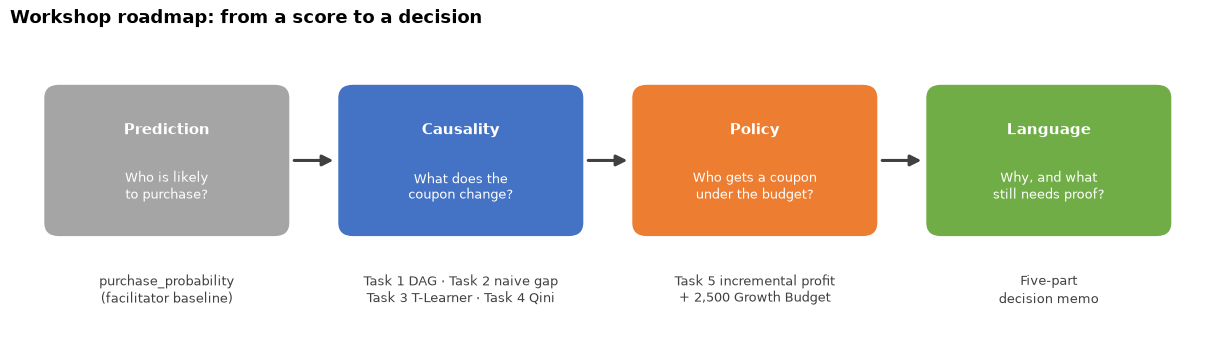

In [3]:
plot_workshop_roadmap()

## Meet the data
One row per customer: seven pre-coupon features, whether last month's campaign
sent a coupon (`coupon_sent`), whether the customer bought within 7 days
(`purchased_7d`), and two money columns for the policy at the end. Nothing to
code here: run the cells and answer the questions below them.

In [4]:
overview = pd.Series(
    {
        "customers": len(observed),
        "share sent a coupon": observed["coupon_sent"].mean(),
        "7-day purchase rate": observed["purchased_7d"].mean(),
        "mean order margin": observed["expected_order_margin"].mean(),
        "mean coupon cost": observed["expected_coupon_cost"].mean(),
        "cost to coupon everyone": observed["expected_coupon_cost"].sum(),
        "Growth Budget": GROWTH_BUDGET,
    }
).round(3)
overview

customers                  10000.000
share sent a coupon            0.297
7-day purchase rate            0.238
mean order margin             10.691
mean coupon cost               1.655
cost to coupon everyone    16550.320
Growth Budget               2500.000
dtype: float64

In [5]:
observed[FEATURES].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
days_since_last_purchase,10000.0,26.98,20.06,0.20,12.50,22.10,35.70,120.00
orders_30d,10000.0,2.40,1.77,0.00,1.00,2.00,3.00,11.00
app_sessions_30d,10000.0,4.66,2.68,0.00,3.00,4.00,6.00,19.00
average_order_value,10000.0,14.85,3.80,5.00,12.16,14.88,17.56,28.17
loyalty_score,10000.0,0.52,0.22,0.01,0.36,0.53,0.70,1.00
price_sensitivity,10000.0,0.50,0.19,0.02,0.35,0.50,0.64,0.97
offer_affinity,10000.0,0.50,0.19,0.04,0.36,0.50,0.65,0.97


- Roughly what share of customers can the Growth Budget pay a coupon for?
  What does that mean for the order in which we pick them?
- A coupon costs about 1.7 and a purchase earns about 10.7 in margin. How many
  percentage points must the coupon raise a customer's purchase probability
  before it pays for itself?

The old AI ranks customers by predicted purchase probability. High reported
ROI made the campaign look successful — until the audit.

In [6]:
observed["purchase_probability"] = fit_purchase_baseline(observed)
observed[["customer_id", "purchase_probability", "coupon_sent", "purchased_7d"]].head()

,customer_id,purchase_probability,coupon_sent,purchased_7d
0,CAFE-000001,0.256251,0,0
1,CAFE-000002,0.258430,1,1
2,CAFE-000003,0.260550,0,0
3,CAFE-000004,0.260552,0,0
4,CAFE-000005,0.497132,0,1


A high purchase probability tells you a customer buys. It does not tell you
whether the coupon is the reason. Which of these four boxes does the old
model fill its target list from?

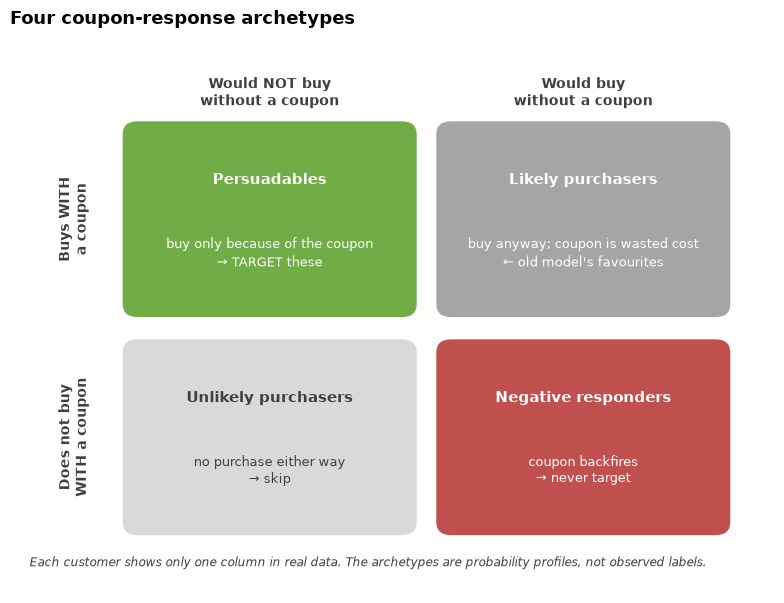

In [7]:
plot_uplift_archetypes()

## Task 1 - Specify the question (worksheet)
In the cell below, write your answers as plain text:

- treatment
- outcome
- three plausible confounders
- one variable you must NOT control for because it happens after treatment
- a one-line DAG sketch
- the supplied funding rule (headquarters Growth Budget)

### Task 1 — reference answer

- **Treatment:** `coupon_sent`, the decision to send the 20% coupon.
- **Outcome:** `purchased_7d`, purchase within seven days.
- **Three plausible confounders:** `loyalty_score`, `orders_30d`, and `days_since_last_purchase`; these customer-history measures can influence both assignment and purchase.
- **Do not adjust for:** coupon redemption or browsing measured after coupon delivery, because these can be downstream of treatment.
- **DAG:** pre-coupon X → coupon_sent; pre-coupon X → purchased_7d; coupon_sent → purchased_7d. Use the seven supplied pre-treatment features; causal interpretation assumes they capture the relevant common causes and that overlap holds.
- **Funding rule:** headquarters supplies a fixed 2,500 Growth Budget. Spend expected coupon cost, accept only positive estimated incremental profit, and respect the budget.


### Check your DAG (run after the group discussion)

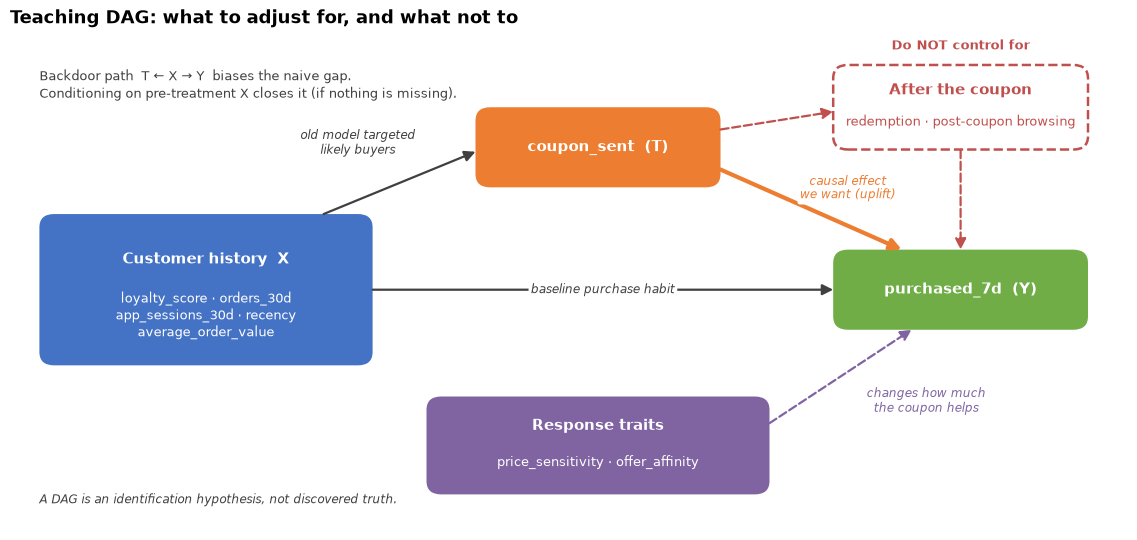

In [8]:
plot_causal_dag()

## Task 2 - Naive observed difference
Compute E[Y|T=1] - E[Y|T=0]. This is what we observed, not what we want.
It must NOT be labeled ATE.

In [9]:
def naive_observed_difference(df: pd.DataFrame) -> float:
    treated = df.loc[df["coupon_sent"] == 1, "purchased_7d"].mean()
    control = df.loc[df["coupon_sent"] == 0, "purchased_7d"].mean()
    return float(treated - control)


naive = naive_observed_difference(observed)
print("naive observed difference:", naive)

naive observed difference: 0.13819725079316023


### Why the naive gap is biased: balance and overlap
Nothing to code: run both cells and read the evidence. If the coupon group
already looked different *before* any coupon, part of the gap is the backdoor
path T ← X → Y from the DAG, not the coupon.

The **standardized mean difference** (SMD) puts every feature on one scale:
the gap in group means divided by the pooled standard deviation. |SMD| > 0.1
is the usual line for "imbalanced".

In [10]:
treated_x = observed.loc[observed["coupon_sent"] == 1, FEATURES]
control_x = observed.loc[observed["coupon_sent"] == 0, FEATURES]
balance = pd.DataFrame({"no coupon": control_x.mean(), "coupon": treated_x.mean()})
balance["SMD"] = (treated_x.mean() - control_x.mean()) / np.sqrt(
    (treated_x.var() + control_x.var()) / 2
)
balance.round(3)

,no coupon,coupon,SMD
days_since_last_purchase,28.050,24.453,-0.183
orders_30d,2.290,2.647,0.198
app_sessions_30d,4.510,5.026,0.191
average_order_value,14.624,15.378,0.198
loyalty_score,0.507,0.565,0.261
price_sensitivity,0.501,0.491,-0.048
offer_affinity,0.502,0.506,0.023


Adjusting for X only works where comparable customers exist in **both**
groups (overlap, or positivity). The **propensity score** P(coupon | X) is the
probability the old campaign would have sent this customer a coupon. If some
customers had a propensity near 0 or 1, one of the T-Learner's two models
would have to guess for them with no data.

propensity range:           0.12 - 0.52
share outside [0.05, 0.95]: 0.0%


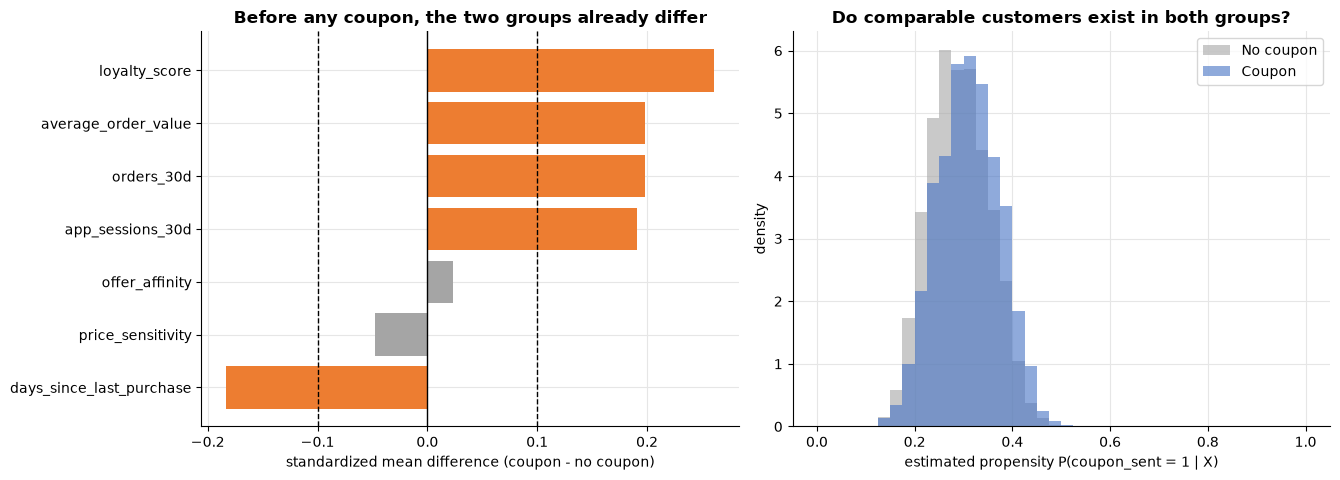

In [11]:
propensity_model = LogisticRegression(max_iter=2000).fit(observed[FEATURES], observed["coupon_sent"])
propensity = propensity_model.predict_proba(observed[FEATURES])[:, 1]
print(f"propensity range:           {propensity.min():.2f} - {propensity.max():.2f}")
print(f"share outside [0.05, 0.95]: {((propensity < 0.05) | (propensity > 0.95)).mean():.1%}")
plot_confounding_overlap(balance["SMD"], propensity, observed["coupon_sent"])

- Which features cross |SMD| = 0.1? Did the old campaign send coupons to
  *better* or *worse* customers, so does the naive gap overstate or
  understate the coupon's effect?
- `price_sensitivity` and `offer_affinity` are balanced. Find them in the DAG:
  why keep them in the model anyway?
- Do the two histograms overlap across the whole range? Write the propensity
  range into memo section 2 (identification assumptions).

## Task 3 - Train a T-Learner, then test it on unseen customers
Real models are judged on data they never saw. Hold out 30% of the customers,
train on the other 70%.

In [12]:
train, test = split_train_test(observed)
print(f"train: {len(train):,} customers · test: {len(test):,} customers")

train: 7,000 customers · test: 3,000 customers


Split `train` by `coupon_sent`, fit one outcome model per arm on FEATURES,
and return the fitted control model first, then the treated model. Keep these
models so they can be saved and reused without training again. The provided
prediction function computes mu0, mu1 and uplift = mu1 - mu0.
`make_model` builds a fresh classifier each time you call it.

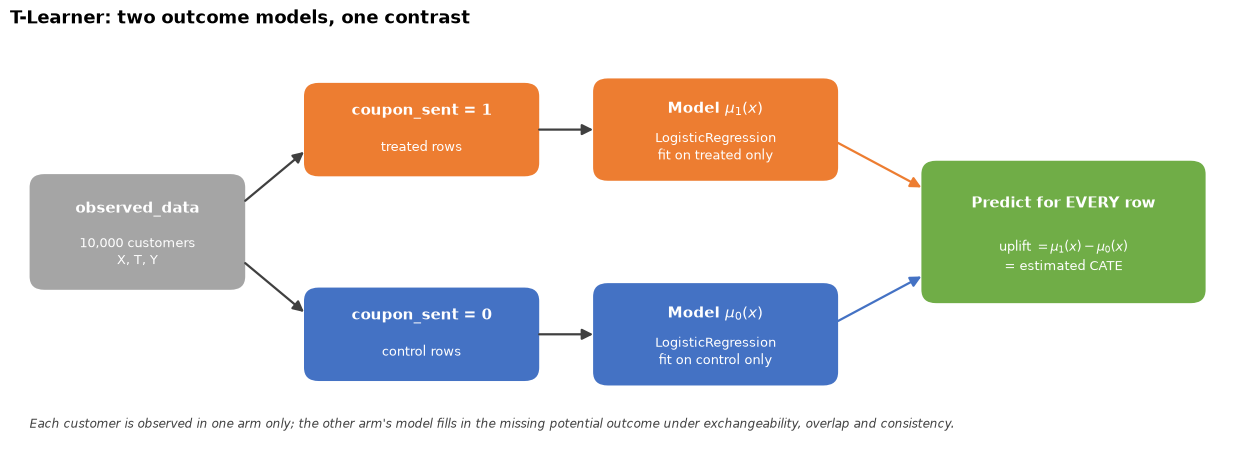

In [13]:
plot_t_learner_schematic()

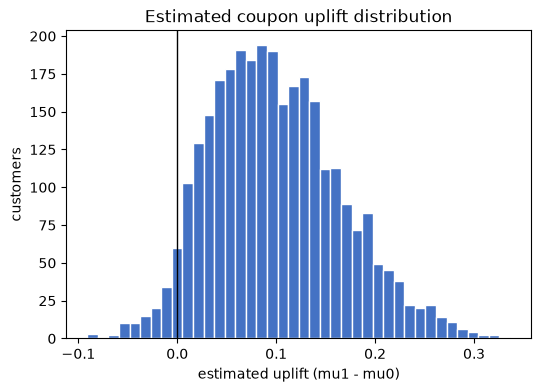

In [14]:
def make_logistic():
    return LogisticRegression(max_iter=2000)


def fit_t_learner(train, features=FEATURES, make_model=make_logistic):
    treated = train[train["coupon_sent"] == 1]
    control = train[train["coupon_sent"] == 0]
    model_treated = make_model().fit(treated[features], treated["purchased_7d"])
    model_control = make_model().fit(control[features], control["purchased_7d"])
    return model_control, model_treated


def predict_t_learner(model_control, model_treated, score, features=FEATURES):
    mu0 = model_control.predict_proba(score[features])[:, 1]
    mu1 = model_treated.predict_proba(score[features])[:, 1]
    return mu0, mu1, mu1 - mu0


def t_learner_uplift(train, score, features=FEATURES, make_model=make_logistic):
    model_control, model_treated = fit_t_learner(train, features, make_model)
    return predict_t_learner(model_control, model_treated, score, features)


model_control, model_treated = fit_t_learner(train)
model_path = save_bundle(
    {"kind": "t", "features": list(FEATURES),
     "model_control": model_control, "model_treated": model_treated},
    Path("artifacts/models/t_learner.joblib"), training_rows=len(train), split_seed=42,
)
restored = load_bundle(model_path)
model_control, model_treated = restored["model_control"], restored["model_treated"]
mu0, mu1, uplift = predict_t_learner(model_control, model_treated, test)
plot_uplift_distribution(uplift)

In [15]:
break_even = (test["expected_coupon_cost"] / test["expected_order_margin"]).to_numpy()
print(f"mean uplift:            {uplift.mean():+.3f}")
print(f"share with uplift < 0:  {(uplift < 0).mean():.1%}")
print(f"share above break-even: {(uplift > break_even).mean():.1%}")

mean uplift:            +0.099
share with uplift < 0:  4.1%
share above break-even: 22.9%


- Compare the mean uplift with the naive gap from Task 2. Which way did
  adjusting for X move it, and does that match what the balance table said?
- If the average customer is below break-even, why can a targeted campaign
  still make money?

**Is each outcome model any good?** Check it the way you would any classifier:
AUC on the held-out customers of its own arm.

In [16]:
def held_out_auc(test, mu0, mu1):
    treated = test["coupon_sent"].to_numpy() == 1
    y = test["purchased_7d"].to_numpy()
    return roc_auc_score(y[~treated], mu0[~treated]), roc_auc_score(y[treated], mu1[treated])


print("logistic  AUC mu0 %.3f · mu1 %.3f" % held_out_auc(test, mu0, mu1))

logistic  AUC mu0 0.688 · mu1 0.684


### Swap in a stronger model
Gradient boosting usually beats logistic regression on tabular data. Pass it
in and compare. Which model would you ship?

In [17]:
def make_boosting():
    return HistGradientBoostingClassifier(random_state=0)


gb_control, gb_treated = fit_t_learner(train, make_model=make_boosting)
gb_path = save_bundle(
    {"kind": "t", "features": list(FEATURES),
     "model_control": gb_control, "model_treated": gb_treated},
    Path("artifacts/models/t_learner_boosting.joblib"), training_rows=len(train), split_seed=42,
)
boosting_bundle = load_bundle(gb_path)
mu0_gb, mu1_gb = predict_outcomes(boosting_bundle, test)
uplift_gb = mu1_gb - mu0_gb
print("boosting  AUC mu0 %.3f · mu1 %.3f" % held_out_auc(test, mu0_gb, mu1_gb))

boosting  AUC mu0 0.646 · mu1 0.636


### S-Learner: one model, two treatment settings
One classifier learns from X, coupon_sent, and explicit X * coupon_sent
interactions. Predict each customer twice, holding X fixed and setting the
coupon indicator first to 0, then 1. Compare this with the two-model T-Learner.
All candidates are saved and reloaded before evaluation; evaluation never fits.

In [18]:
s_path = save_bundle(
    fit_s_learner(train, FEATURES), Path("artifacts/models/s_learner.joblib"),
    training_rows=len(train), split_seed=42,
)
s_bundle = load_bundle(s_path)
mu0_s, mu1_s = predict_outcomes(s_bundle, test)
print("S-Learner AUC mu0 %.3f · mu1 %.3f" % held_out_auc(test, mu0_s, mu1_s))

S-Learner AUC mu0 0.688 · mu1 0.684


### Stretch (finished early?) break the DAG on purpose
Your function takes a `features` argument. Re-run it without some confounders
and compare the mean uplift with the naive difference from Task 2:

1. drop only `loyalty_score`;
2. drop all five customer-history features (`days_since_last_purchase`,
   `orders_30d`, `app_sessions_30d`, `average_order_value`, `loyalty_score`).

What happens in each case, and why is the first one so mild?

## Task 4 - Check the uplift ranking on the randomized pilot
AUC checks predictions of *purchase*. It cannot check *uplift*: nobody is
observed both with and without a coupon. Last month headquarters ran a small
pilot where a coin decided who got a coupon, so there the two groups are
comparable. Rank the pilot customers by a score and count the extra purchases
we would have captured:

gain at the top k = treated buyers - control buyers × (treated count / control count)

Plotting that gain against the share of customers targeted gives a **Qini
curve**. A ranking that puts the persuadable customers first rises fastest.

pilot: 5,000 customers · coupon rate 49.2%


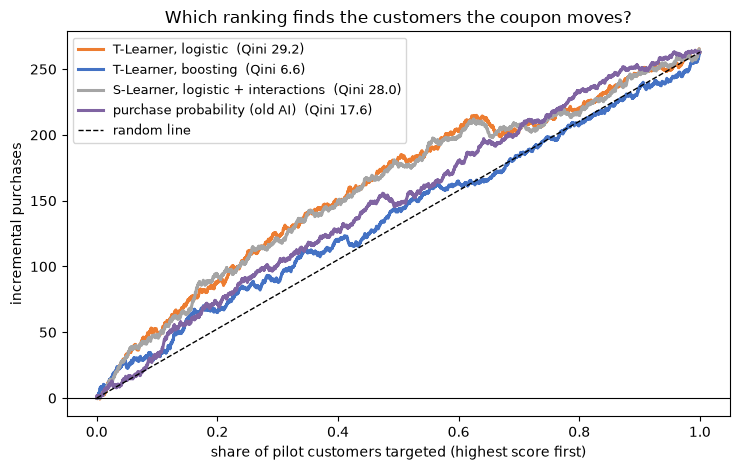

In [19]:
pilot = load_pilot_data()
print(f"pilot: {len(pilot):,} customers · coupon rate {pilot['coupon_sent'].mean():.1%}")


def qini_curve(pilot, score):
    order = np.argsort(-np.asarray(score))
    treated = pilot["coupon_sent"].to_numpy()[order]
    bought = pilot["purchased_7d"].to_numpy()[order]
    n_treated = np.cumsum(treated)
    n_control = np.cumsum(1 - treated)
    buyers_treated = np.cumsum(bought * treated)
    buyers_control = np.cumsum(bought * (1 - treated))
    scale = np.divide(n_treated, n_control, out=np.zeros(len(order)), where=n_control > 0)
    gain = buyers_treated - buyers_control * scale
    share = np.arange(1, len(order) + 1) / len(order)
    return pd.DataFrame({"share": share, "gain": gain})


baseline_model = LogisticRegression(max_iter=2000).fit(train[FEATURES], train["purchased_7d"])
curves = {
    "T-Learner, logistic": qini_curve(pilot, predict_uplift(restored, pilot)),
    "T-Learner, boosting": qini_curve(pilot, predict_uplift(boosting_bundle, pilot)),
    "S-Learner, logistic + interactions": qini_curve(pilot, predict_uplift(s_bundle, pilot)),
    "purchase probability (old AI)": qini_curve(pilot, baseline_model.predict_proba(pilot[FEATURES])[:, 1]),
}
plot_qini_curves(curves)

The dashed line is random targeting (Qini 0). Which model won on AUC? Which
one won on the pilot? For the shared classroom reference we keep the logistic
T-Learner policy below. Model selection would require a separate final evaluation.

## Task 5 - Campaign policy and decision memo
expected_incremental_profit = uplift * expected_order_margin - expected_coupon_cost

Score every customer with your chosen model, compute the expected incremental
profit, and let `select_under_budget(profit, cost, GROWTH_BUDGET)` pick
positive-value customers until the Growth Budget is spent. Write
artifacts/customer_scores.csv with columns ARTIFACT_COLUMNS.

In [20]:
def build_customer_scores(df, uplift):
    margin = df["expected_order_margin"].to_numpy()
    cost = df["expected_coupon_cost"].to_numpy()
    profit = uplift * margin - cost
    return pd.DataFrame(
        {
            "customer_id": df["customer_id"].to_numpy(),
            "purchase_probability": df["purchase_probability"].to_numpy(),
            "estimated_uplift": uplift,
            "expected_incremental_profit": profit,
            "recommended": select_under_budget(profit, cost, GROWTH_BUDGET),
        }
    )[ARTIFACT_COLUMNS]


uplift_all = predict_t_learner(model_control, model_treated, observed)[2]
scores = build_customer_scores(observed, uplift_all)
Path("artifacts").mkdir(parents=True, exist_ok=True)
scores.to_csv("artifacts/customer_scores.csv", index=False)
scores.head()

,customer_id,purchase_probability,estimated_uplift,expected_incremental_profit,recommended
0,CAFE-000001,0.256251,0.122513,-0.151683,0
1,CAFE-000002,0.258430,0.180146,0.441895,1
2,CAFE-000003,0.260550,0.134149,-0.260465,0
3,CAFE-000004,0.260552,0.137149,-0.132440,0
4,CAFE-000005,0.497132,0.075893,-1.480808,0


### Check the loaded model used by your policy
Task 3 already saved and loaded the models. The policy above and all plots
below use those loaded models' predictions. The final Colab cell downloads
the fitted logistic T-Learner and its version metadata.

In [21]:
restored_uplift = predict_uplift(restored, observed)
np.testing.assert_allclose(restored_uplift, uplift_all, rtol=1e-12)
print(f"Saved and reloaded: {model_path} ({model_path.stat().st_size:,} bytes)")

Saved and reloaded: artifacts\models\t_learner.joblib (1,175 bytes)


### Check your policy
These are the numbers your decision memo needs. The facilitator will show how
the policy performs against the simulator's truth on the projector.

In [22]:
chosen = scores["recommended"] == 1
spend = observed.loc[chosen, "expected_coupon_cost"].sum()
print(f"customers recommended:        {chosen.sum():,}")
print(f"expected coupon spend:        {spend:,.2f} / {GROWTH_BUDGET:,.0f}")
print(f"expected incremental orders:  {scores.loc[chosen, 'estimated_uplift'].sum():,.1f}")
print(f"expected incremental profit:  {scores.loc[chosen, 'expected_incremental_profit'].sum():,.2f}")
print(f"mean estimated uplift (ATE):  {scores['estimated_uplift'].mean():+.3f}")

customers recommended:        1,691
expected coupon spend:        2,499.84 / 2,500
expected incremental orders:  333.2
expected incremental profit:  927.19
mean estimated uplift (ATE):  +0.098


## Results board
Nothing to code: run these cells once Task 5 works and answer the questions
under each chart. Every chart is built from your own model, so it shows
exactly what your analysis claims. The numbers go into your decision memo.

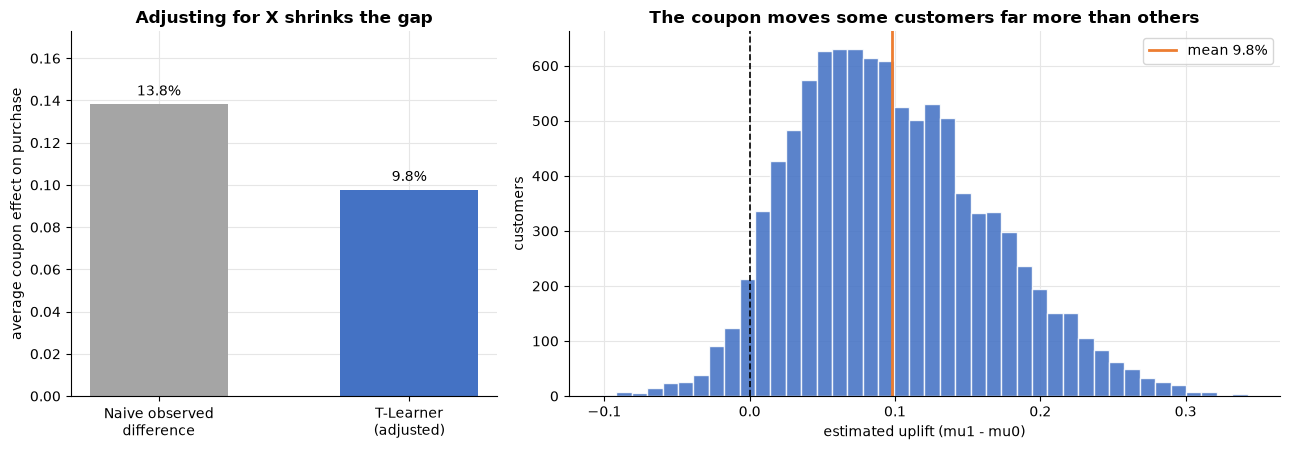

In [23]:
plot_effect_summary(naive, uplift_all)

- How much of the naive gap was confounding, and how much is the coupon?
  (Memo section 1.)
- Look at the spread: would a single "average effect" be enough to decide
  who gets a coupon?

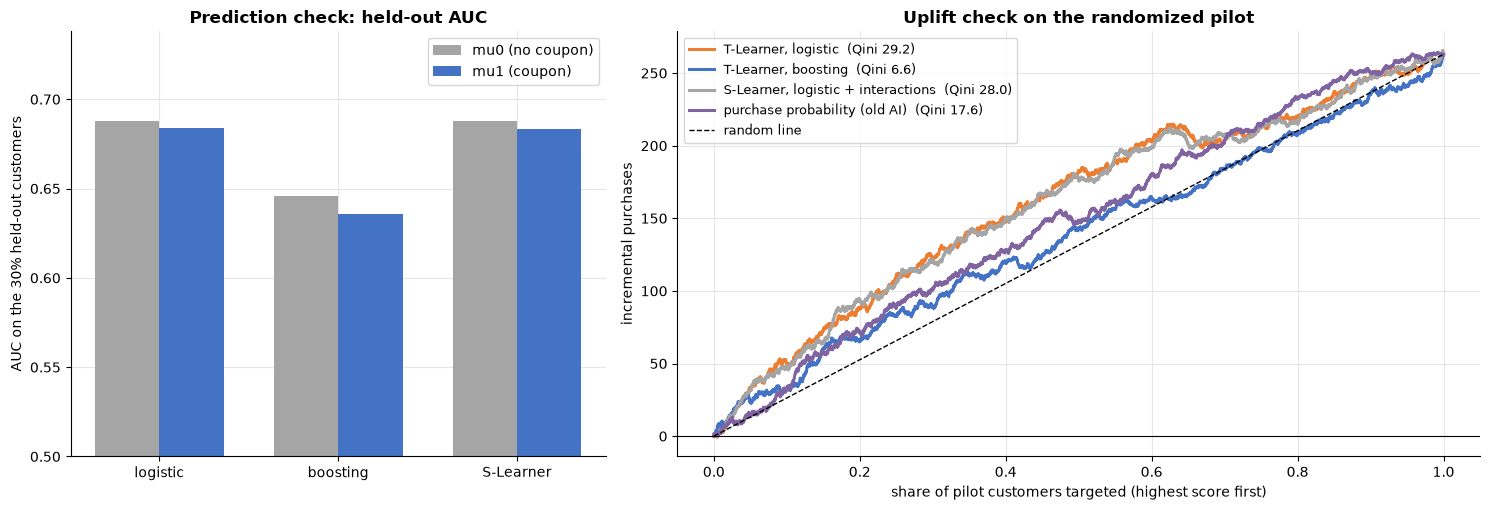

In [24]:
auc = {
    "logistic": held_out_auc(test, mu0, mu1),
    "boosting": held_out_auc(test, mu0_gb, mu1_gb),
    "S-Learner": held_out_auc(test, mu0_s, mu1_s),
}
plot_model_check(auc, curves)

- Did the two checks agree on the winner? Which check would you trust if they
  disagreed, and why? (Memo section 5.)

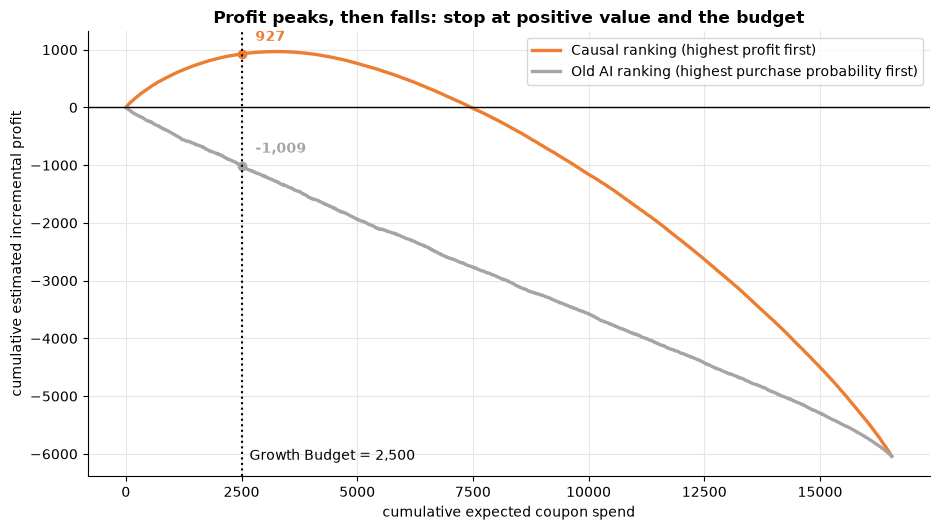

In [25]:
plot_budget_curve(
    scores["expected_incremental_profit"].to_numpy(),
    observed["expected_coupon_cost"].to_numpy(),
    scores["purchase_probability"].to_numpy(),
    GROWTH_BUDGET,
)

- Where does the orange curve peak, and is that before or after the Growth
  Budget line? What does that say about whether the budget binds?
- Why does the grey curve fall as the old AI spends more?

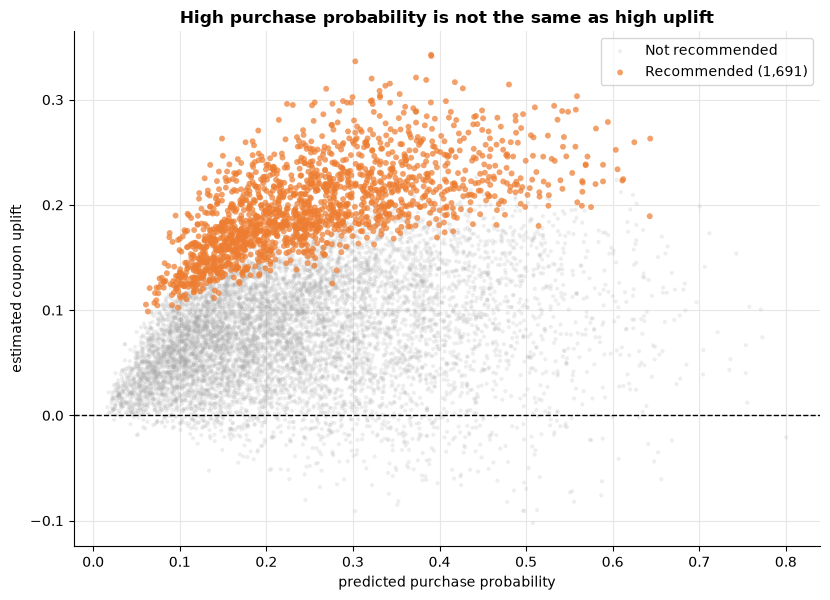

In [26]:
plot_targeting_map(scores["purchase_probability"], scores["estimated_uplift"], scores["recommended"])

### Who did each list pick?
Same budget, two rankings: your causal list, and the old AI's list (highest
purchase probability first). Both are scored with *your* estimates.

In [27]:
cost = observed["expected_coupon_cost"].to_numpy()
old_ai = select_under_budget(scores["purchase_probability"].to_numpy(), cost, GROWTH_BUDGET)
target_lists = {"causal list": scores["recommended"].to_numpy() == 1, "old AI list": old_ai == 1}
list_profile = pd.DataFrame(
    {
        name: {
            "customers": mask.sum(),
            "spend": cost[mask].sum(),
            "mean coupon cost": cost[mask].mean(),
            "mean purchase probability": scores.loc[mask, "purchase_probability"].mean(),
            "mean estimated uplift": scores.loc[mask, "estimated_uplift"].mean(),
            "estimated incremental profit": scores.loc[mask, "expected_incremental_profit"].sum(),
        }
        for name, mask in target_lists.items()
    }
).round(3)
list_profile

,causal list,old AI list
customers,1691.000,962.000
spend,2499.840,2500.000
mean coupon cost,1.478,2.599
mean purchase probability,0.256,0.508
mean estimated uplift,0.197,0.118
estimated incremental profit,927.187,-1009.340


- The old AI's customers buy more often. Why does its list still lose money?
- On the targeting map, find the high-probability, low-uplift corner. Which
  of the four archetypes from the start of the session live there?
  (Memo section 4.)

## Reveal - watch the projector
The simulator knows every customer's true effect, which real data never does.
The facilitator will compare the estimate and the targeting policy with that
truth on the projector.

In [28]:
from IPython.display import Markdown, display
display(Markdown(f"""### Decision memo — executed reference answer

**1. Estimated effect.** The naive gap is {naive:.2%}, but it is not an ATE: pre-coupon customer history differs between the treatment groups. Adjusting for the supplied features gives a mean estimated uplift of {scores['estimated_uplift'].mean():.2%}; estimated effects vary across customers.

**2. Identification assumptions.** Exchangeability requires the measured pre-coupon features to capture common causes. A possible missing variable in a real deployment is current purchasing intent; the simulator is constructed with observed common causes. Estimated propensity ranges {propensity.min():.3f}–{propensity.max():.3f}; {((propensity < .05) | (propensity > .95)).mean():.1%} of customers fall outside [0.05, 0.95]. Consistency requires the same coupon type and seven-day outcome definition. Do not adjust for post-coupon redemption or browsing.

**3. Budget impact.** Recommend {int(chosen.sum()):,} customers, spending {spend:,.2f} of {GROWTH_BUDGET:,.2f}, for estimated incremental profit {scores.loc[chosen, 'expected_incremental_profit'].sum():,.2f}. The old-AI list has estimated incremental profit {list_profile.loc['estimated incremental profit', 'old AI list']:,.2f} under the same budget.

**4. Recommended action.** For the shared classroom reference, use the loaded logistic T-Learner and target positive estimated incremental profit in descending order, stopping at the budget. Effect uncertainty and model assumptions still need validation.

**5. What still needs validation.** Randomized-pilot Qini is {qini_coefficient(curves['T-Learner, logistic']):.2f} for logistic T, {qini_coefficient(curves['T-Learner, boosting']):.2f} for boosting T, {qini_coefficient(curves['S-Learner, logistic + interactions']):.2f} for S-Learner, and {qini_coefficient(curves['purchase probability (old AI)']):.2f} for old AI. Confirm the final targeting policy in a separate randomized holdout, including actual coupon costs and profit; the pilot used for comparison is not a fresh final validation.
"""))

### Decision memo — executed reference answer

**1. Estimated effect.** The naive gap is 13.82%, but it is not an ATE: pre-coupon customer history differs between the treatment groups. Adjusting for the supplied features gives a mean estimated uplift of 9.77%; estimated effects vary across customers.

**2. Identification assumptions.** Exchangeability requires the measured pre-coupon features to capture common causes. A possible missing variable in a real deployment is current purchasing intent; the simulator is constructed with observed common causes. Estimated propensity ranges 0.123–0.521; 0.0% of customers fall outside [0.05, 0.95]. Consistency requires the same coupon type and seven-day outcome definition. Do not adjust for post-coupon redemption or browsing.

**3. Budget impact.** Recommend 1,691 customers, spending 2,499.84 of 2,500.00, for estimated incremental profit 927.19. The old-AI list has estimated incremental profit -1,009.34 under the same budget.

**4. Recommended action.** For the shared classroom reference, use the loaded logistic T-Learner and target positive estimated incremental profit in descending order, stopping at the budget. Effect uncertainty and model assumptions still need validation.

**5. What still needs validation.** Randomized-pilot Qini is 29.21 for logistic T, 6.57 for boosting T, 28.04 for S-Learner, and 17.63 for old AI. Confirm the final targeting policy in a separate randomized holdout, including actual coupon costs and profit; the pilot used for comparison is not a fresh final validation.


## Download your trained model (Google Colab)
Run this after completing all four TODOs. The ZIP contains both fitted models
in one joblib bundle and a readable JSON with feature order and versions.
To predict later: load the bundle, select its `features` in order, and subtract
control-model purchase probability from treated-model purchase probability.
Use the recorded package versions and load only model files you trust.

In [29]:
import zipfile

model_archive = model_path.with_suffix(".zip")
with zipfile.ZipFile(model_archive, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    archive.write(model_path, arcname=model_path.name)
    archive.write(model_path.with_suffix(".json"), arcname=model_path.with_suffix(".json").name)

try:
    from google.colab import files
except ImportError:
    print(f"Model download ready: {model_archive.resolve()}")
else:
    files.download(str(model_archive.resolve()))

Model download ready: D:\Club\GDG\casual_ml\artifacts\workshop_answer_copy_20261015\artifacts\models\t_learner.zip
